# Solar Flare Class Prediction (next 24 h) — 1D CNN on the clean dataset

Same data, split, features and metrics as the XGBoost, LSTM and DLSTM notebooks on `clean_flares_dataaset.csv`, so all compare directly.

**Model:** a **fully convolutional network (FCN)**, the standard 1D CNN for multivariate time-series classification (Wang, Yan & Oates 2017) and one of the deep-learning baselines in Li et al. (2025). It slides convolution filters along each region's last `SEQ_LEN` hours of SHARP parameters to find short-term patterns, then averages them over the window:
- 3 blocks of Conv1D → batch norm → ReLU with 128, 256, 128 filters and kernel sizes 8, 5, 3
- global average pooling over time → dense layer → softmax over flare classes

The layer sizes follow the standard FCN; they were not checked against Li et al.'s exact configuration. Li et al.'s data augmentation is not included here (class-weighted loss is used instead, as in the other notebooks).

| Column | Use |
|---|---|
| `label` | Target: biggest flare in the next 24 h — **none / C / M / X** (A/B flares count as none). `LABEL_SCHEME = "goes"` keeps B separate (the dataset has no A-class flares). |
| `split` | **Chronological** train (2010–2021) / validation (2021–2023) / test (2023–2026) split, as in the proposal. No region appears in more than one split. |
| 16 SHARP parameters | Model inputs (large ones log-scaled). |
| `usable` | Rows with `usable = 0` have no SHARP data and are not forecast. |
| `filled` | Marks hours carried forward from the previous reading; given to the model as an extra input. |
| `mx` | Used for the binary score (M/X vs the rest). |

Metrics: AUC, precision, recall, F1 and **TSS per class, averaged**.

**Full-dataset mode:** `SAMPLE_FRAC = None` trains and tests on every active region (2010–2026). Use a **T4 GPU** runtime (Runtime → Change runtime type → T4 GPU). For a quick test that runs in a few minutes, set `SAMPLE_FRAC = 0.05` (5% of regions per split).

In [ ]:
# WHAT: Nothing to install; PyTorch and pandas come with Colab.
# OUTPUT: None.

# PyTorch and pandas are pre-installed on Colab

## 1. Load data

In [ ]:
# WHAT: Run settings (sample size, window length, labels, options) and where the data file is; connects Google Drive.
# OUTPUT: 'Mounted at /content/drive' and the file size (should be ~121 MB).

import os
# --- where the data is --------------------------------------------------------
USE_DRIVE = True    # True = load from Google Drive (recommended); False = upload the file when prompted
DRIVE_PATH = '/content/drive/MyDrive/DS440/clean_flares_dataaset.csv'   # edit if the file is elsewhere
DATA_PATH = "clean_flares_dataaset.csv"

# --- run settings -------------------------------------------------------------
SAMPLE_FRAC = None       # None = full dataset; 0.05 = quick test on 5% of regions per split
SEQ_LEN = 24             # hours of history per forecast
LABEL_SCHEME = "label"   # "label" = none/C/M/X (dataset's label column);  "goes" = none/B/C/M/X from GOES_CLASS
USE_FLARE_HISTORY = True   # adds the past-24h GOES flare peak as a feature (see section 2); False = SHARP only
ALWAYS_INCLUDE = [11149]   # HARPNUM of NOAA AR 13664 (May 2024 storm) - kept in the smoke-test sample so section 8 can show it
RANDOM_STATE = 42

if USE_DRIVE:
    from google.colab import drive; drive.mount('/content/drive')
    DATA_PATH = DRIVE_PATH
elif not os.path.exists(DATA_PATH):
    from google.colab import files
    DATA_PATH = next(iter(files.upload()))

print(f"{os.path.getsize(DATA_PATH)/1e6:.1f} MB  (should be ~121 MB; less means the upload is incomplete)")

Mounted at /content/drive
121.0 MB  (should be ~121 MB; less means the upload is incomplete)


In [ ]:
# WHAT: Loads the CSV, converts 'time' to dates, summarizes each split, and (if SAMPLE_FRAC is set) keeps only a
#       fraction of regions per split for a quick test (plus ALWAYS_INCLUDE).
# OUTPUT: Row/region counts, a table of each split's date range, the smoke-test region count, and the first 5 rows.

import numpy as np, pandas as pd
full = pd.read_csv(DATA_PATH, low_memory=False)
full["time"] = pd.to_datetime(full["time"], format="%m/%d/%Y %H:%M")
print(full.shape, "|", full.time.min(), "->", full.time.max(), "|", full.HARPNUM.nunique(), "regions")
print(full.groupby("split").agg(rows=("time", "size"), start=("time", "min"), end=("time", "max"), regions=("HARPNUM", "nunique")))

if SAMPLE_FRAC:
    rng = np.random.default_rng(RANDOM_STATE)
    keep = []
    for s, g in full.groupby("split"):
        h = g.HARPNUM.unique()
        keep += list(rng.choice(h, size=max(1, int(len(h) * SAMPLE_FRAC)), replace=False))
    keep += [h for h in ALWAYS_INCLUDE if h in set(full.HARPNUM) and h not in keep]
    full = full[full.HARPNUM.isin(keep)]
    print(f"\nSmoke test: kept {len(keep)} regions, {len(full):,} rows")
full.head()

(675750, 25) | 2010-05-01 00:00:00 -> 2026-08-06 00:00:00 | 2610 regions
         rows               start                 end  regions
split                                                         
test   247834 2023-01-03 18:00:00 2026-08-06 00:00:00      899
train  347344 2010-05-01 00:00:00 2021-01-03 16:00:00     1387
val     80572 2021-01-09 02:00:00 2023-01-14 19:00:00      324


,HARPNUM,NOAA_AR,time,split,label,mx,GOES_CLASS,USFLUX,MEANGBZ,MEANJZD,...,TOTUSJH,ABSNJZH,SAVNCPP,MEANPOT,TOTPOT,MEANSHR,SHRGT45,R_VALUE,filled,usable
0,1,11067,2010-05-01 00:00:00,train,C,0.0,C8.1,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
1,1,11067,2010-05-01 01:00:00,train,C,0.0,C8.1,7.361199e+21,80.902,0.109558,...,316.165,5.010,8.021210e+11,2133.142,3.083054e+22,21.730,6.377,3.332,0,1
2,1,11067,2010-05-01 02:00:00,train,none,0.0,B1.2,7.909655e+21,80.915,0.076309,...,347.682,58.043,3.337758e+12,2119.635,3.468324e+22,22.715,8.839,3.262,0,1
3,1,11067,2010-05-01 03:00:00,train,none,0.0,B1.2,7.723257e+21,105.612,-0.106872,...,392.140,27.802,1.972685e+12,2859.284,4.723407e+22,25.096,11.488,3.247,0,1
4,1,11067,2010-05-01 04:00:00,train,none,0.0,B1.2,7.417460e+21,107.862,-0.006745,...,354.518,38.681,2.209957e+12,2790.776,4.298908e+22,23.546,10.501,3.170,0,1


## 2. Prepare features and targets
- Large SHARP quantities are log-scaled.
- Optional **GOES flare-history feature** (`USE_FLARE_HISTORY = True`): log10 peak flux of the biggest flare the region produced in the **previous** 24 h, taken from the same region's `GOES_CLASS` 24 h earlier (whose window ends at the current hour, so no future information is used). This is closer to the paper's GOES peak-flux input.

In [ ]:
# WHAT: Log-scales the very large SHARP values, chooses the input features, optionally adds the past-24h flare
#       feature, sets the target classes (none/C/M/X), and marks which rows can be forecast (labelled + usable).
# OUTPUT: The feature list, the class list, and a table of class counts per split.

full = full.sort_values(["HARPNUM", "time"]).reset_index(drop=True)
SHARP = ["USFLUX", "MEANGBZ", "MEANJZD", "TOTUSJZ", "MEANALP", "MEANGBT", "MEANGBH", "MEANJZH",
         "TOTUSJH", "ABSNJZH", "SAVNCPP", "MEANPOT", "TOTPOT", "MEANSHR", "SHRGT45", "R_VALUE"]
for c in ["USFLUX", "TOTUSJZ", "SAVNCPP", "TOTPOT", "TOTUSJH", "ABSNJZH"]:
    full[c] = np.sign(full[c]) * np.log1p(np.abs(full[c]))
feature_cols = SHARP + ["filled"]

SCALE = {"A": 1e-8, "B": 1e-7, "C": 1e-6, "M": 1e-5, "X": 1e-4}
def class_to_flux(s):
    s = str(s).strip()
    if s == "quiet":
        return 1e-9
    try:
        return SCALE[s[0]] * float(s[1:])
    except (KeyError, ValueError, IndexError):
        return np.nan
if USE_FLARE_HISTORY:
    past = full[["HARPNUM", "time"]].copy()
    past["FLARE_PAST24_LOGFLUX"] = np.log10(full["GOES_CLASS"].map(class_to_flux))
    past["time"] += pd.Timedelta(hours=24)
    full = full.merge(past, on=["HARPNUM", "time"], how="left")
    feature_cols.append("FLARE_PAST24_LOGFLUX")

# Target
if LABEL_SCHEME == "goes":
    g = full["GOES_CLASS"].astype(str)
    full["y_class"] = np.where(g == "quiet", "none", g.str[0])
    full.loc[full["GOES_CLASS"].isna(), "y_class"] = None
    ORDER = ["none", "A", "B", "C", "M", "X"]
else:
    full["y_class"] = full["label"]
    ORDER = ["none", "C", "M", "X"]
classes = [c for c in ORDER if c in set(full["y_class"].dropna())]
cls2id = {c: i for i, c in enumerate(classes)}

# Forecast points: rows with a label and real SHARP data
is_target = full["y_class"].notna() & (full["usable"] == 1)
print("Features:", feature_cols)
print("Classes:", classes)
print(pd.crosstab(full.loc[is_target, "split"], full.loc[is_target, "y_class"])[classes])

Features: ['USFLUX', 'MEANGBZ', 'MEANJZD', 'TOTUSJZ', 'MEANALP', 'MEANGBT', 'MEANGBH', 'MEANJZH', 'TOTUSJH', 'ABSNJZH', 'SAVNCPP', 'MEANPOT', 'TOTPOT', 'MEANSHR', 'SHRGT45', 'R_VALUE', 'filled', 'FLARE_PAST24_LOGFLUX']
Classes: ['none', 'C', 'M', 'X']
y_class    none      C      M     X
split                              
test     159018  41598  13516  1618
train    229374  40947   9929  1196
val       55020  12548   2223   158


## 3. Build sequences
Features are standardized with **training-split statistics only**; missing values become 0 after scaling. For each forecast point (region *R* at hour *t*) the input is hours *t − SEQ_LEN + 1 … t* of region *R*. A final 0/1 column marks real readings; hours before the region appeared, or with `usable = 0`, are zeros with the flag at 0. Windows never cross into another region.

In [ ]:
# WHAT: Standardizes features with training-year statistics, then builds a 24-hour window for every forecast row
#       (that region's last 24 hours; earlier/unusable hours are zero with a real-data flag of 0).
# OUTPUT: Windows, regions and class counts for train/val/test, and the size of the window array.

from sklearn.preprocessing import StandardScaler
from numpy.lib.stride_tricks import sliding_window_view

train_rows = (full["split"] == "train") & (full["usable"] == 1)
scaler = StandardScaler().fit(full.loc[train_rows, feature_cols])
Xs = np.nan_to_num(scaler.transform(full[feature_cols]), nan=0.0).astype(np.float32)
real = (full["usable"].values == 1).astype(np.float32)
Xs = np.concatenate([Xs * real[:, None], real[:, None]], axis=1)      # zero out unusable hours, add flag
n_feat = Xs.shape[1]

pos = full.groupby("HARPNUM").cumcount().values                     # hours since region's first row
target_rows = np.where(is_target.values)[0]
padded = np.concatenate([np.zeros((SEQ_LEN - 1, n_feat), np.float32), Xs])
windows = sliding_window_view(padded, SEQ_LEN, axis=0)              # (rows, feat, SEQ_LEN) view, no copy
seqs = np.ascontiguousarray(windows[target_rows].transpose(0, 2, 1))  # (targets, SEQ_LEN, feat)
lag = np.arange(SEQ_LEN - 1, -1, -1)                                 # steps back from t
seqs[lag[None, :] > pos[target_rows][:, None]] = 0.0                  # drop steps from a previous region
del windows, padded

df = full.loc[target_rows, ["time", "HARPNUM", "NOAA_AR", "split", "y_class", "GOES_CLASS", "mx"]].reset_index(drop=True)
y_all = df["y_class"].map(cls2id).values
train_idx = np.where(df.split == "train")[0]
val_idx   = np.where(df.split == "val")[0]
test_idx  = np.where(df.split == "test")[0]
for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(f"{name:5s}: {len(idx):7,d} windows, {df.HARPNUM.iloc[idx].nunique():4d} regions,",
          dict(zip(classes, np.bincount(y_all[idx], minlength=len(classes)))))
print("Sequence tensor:", seqs.shape, f"({seqs.nbytes/1e6:.0f} MB)")

train: 281,446 windows, 1289 regions, {'none': np.int64(229374), 'C': np.int64(40947), 'M': np.int64(9929), 'X': np.int64(1196)}
val  :  69,949 windows,  324 regions, {'none': np.int64(55020), 'C': np.int64(12548), 'M': np.int64(2223), 'X': np.int64(158)}
test : 215,750 windows,  898 regions, {'none': np.int64(159018), 'C': np.int64(41598), 'M': np.int64(13516), 'X': np.int64(1618)}
Sequence tensor: (567145, 24, 19) (1034 MB)


## 4. Define and train the 1D CNN
Class imbalance is handled with class-weighted loss so rare M/X flares are not ignored. Training keeps the epoch with the best **validation mean TSS** (2021–2022, your primary metric) and stops when it hasn't improved for 5 epochs.

In [ ]:
# WHAT: Sets up data loaders and defines the 1D CNN (FCN): 3 convolution blocks (128/256/128 filters) sliding along
#       the 24-hour window, global average pooling, then a dense layer; loss uses class weights.
# OUTPUT: Device (cpu/cuda), the model structure, and the number of trainable parameters.

import torch, torch.nn as nn, copy
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight

torch.manual_seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

def loader(idx, shuffle):
    ds = TensorDataset(torch.from_numpy(seqs[idx]), torch.from_numpy(y_all[idx].astype(np.int64)))
    return DataLoader(ds, batch_size=256, shuffle=shuffle)
train_dl, val_dl, test_dl = loader(train_idx, True), loader(val_idx, False), loader(test_idx, False)

def conv_block(c_in, c_out, k):
    return nn.Sequential(nn.Conv1d(c_in, c_out, k, padding="same"), nn.BatchNorm1d(c_out), nn.ReLU())

class FCN1D(nn.Module):
    """Fully convolutional network (Wang et al. 2017): 3 conv blocks -> global average pooling -> softmax."""
    def __init__(self, n_feat, n_classes, filters=(128, 256, 128), kernels=(8, 5, 3), dropout=0.3):
        super().__init__()
        chans = (n_feat,) + tuple(filters)
        self.body = nn.Sequential(*[conv_block(chans[i], chans[i + 1], kernels[i]) for i in range(len(filters))])
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(filters[-1], n_classes))
    def forward(self, x):                      # x: (batch, time, features)
        z = self.body(x.transpose(1, 2))       # Conv1d wants (batch, channels, time)
        return self.head(z.mean(dim=2))        # global average pooling over time

model = FCN1D(n_feat, len(classes)).to(device)
w = compute_class_weight("balanced", classes=np.arange(len(classes)), y=y_all[train_idx])
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=device))
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

Device: cuda
FCN1D(
  (body): Sequential(
    (0): Sequential(
      (0): Conv1d(19, 128, kernel_size=(8,), stride=(1,), padding=same)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): Conv1d(128, 256, kernel_size=(5,), stride=(1,), padding=same)
      (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (2): Sequential(
      (0): Conv1d(256, 128, kernel_size=(3,), stride=(1,), padding=same)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
  )
  (head): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=128, out_features=4, bias=True)
  )
)
Trainable parameters: 283652


In [ ]:
# WHAT: Trains the model epoch by epoch; after each epoch it scores the validation years (2021-2022) by mean
#       per-class TSS, keeps the epoch with the best validation TSS, and stops if TSS hasn't improved for 5 epochs.
# OUTPUT: One line per epoch (train loss, val loss, val TSS), 'Early stopping.', and the best validation TSS.

EPOCHS, PATIENCE = 30, 5

def mean_tss(y_true, y_pred):
    """Mean of per-class TSS (one-vs-rest), skipping classes absent from y_true."""
    vals = []
    for k in range(len(classes)):
        t, p = y_true == k, y_pred == k
        if t.any() and (~t).any():
            vals.append(p[t].mean() - p[~t].mean())
    return np.mean(vals)

def run_epoch(dl, train):
    model.train(train)
    total, n, preds = 0.0, 0, []
    with torch.set_grad_enabled(train):
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb); loss = loss_fn(out, yb)
            if train:
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            else:
                preds.append(out.argmax(1).cpu().numpy())
            total += loss.item() * len(yb); n += len(yb)
    return total / n, (np.concatenate(preds) if preds else None)

history, val_tss_hist, best, best_state, bad = [], [], -np.inf, None, 0
for epoch in range(1, EPOCHS + 1):
    tr, _ = run_epoch(train_dl, True)
    va, val_pred = run_epoch(val_dl, False)
    vt = mean_tss(y_all[val_idx], val_pred)
    history.append((tr, va)); val_tss_hist.append(vt)
    print(f"epoch {epoch:2d}  train loss {tr:.4f}  val loss {va:.4f}  val TSS {vt:.3f}")
    if vt > best + 1e-4:
        best, best_state, bad = vt, copy.deepcopy(model.state_dict()), 0
    else:
        bad += 1
        if bad >= PATIENCE:
            print("Early stopping."); break
model.load_state_dict(best_state)
print(f"Best validation mean TSS: {best:.3f} (epoch {int(np.argmax(val_tss_hist)) + 1})")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/conv.py:370: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /pytorch/aten/src/ATen/native/Convolution.cpp:1024.)
  return F.conv1d(


epoch  1  train loss 0.9658  val loss 0.9318  val TSS 0.343
epoch  2  train loss 0.8872  val loss 0.7989  val TSS 0.362
epoch  3  train loss 0.8318  val loss 0.8214  val TSS 0.368
epoch  4  train loss 0.7777  val loss 0.8578  val TSS 0.371
epoch  5  train loss 0.7354  val loss 0.9415  val TSS 0.350
epoch  6  train loss 0.6824  val loss 0.9811  val TSS 0.353
epoch  7  train loss 0.6364  val loss 0.9546  val TSS 0.362
epoch  8  train loss 0.5882  val loss 1.0394  val TSS 0.332
epoch  9  train loss 0.5568  val loss 1.2025  val TSS 0.309
Early stopping.
Best validation mean TSS: 0.371 (epoch 4)


## 5. Evaluate on the test set
Same metrics as the XGBoost notebook. TSS for class *k* (one-vs-rest) = TPR − FPR = TP/(TP+FN) − FP/(FP+TN); reported per class and averaged. Test set = 2023–2026, i.e. future data relative to training.

In [ ]:
# WHAT: Predicts every test window (2023-2026) and computes AUC, precision, recall, F1 and TSS per class + averages.
# OUTPUT: A per-class metrics table and an overall (macro-average) table.

from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix

@torch.no_grad()
def predict_proba(dl):
    model.eval()
    return np.concatenate([torch.softmax(model(xb.to(device)), 1).cpu().numpy() for xb, _ in dl])

proba = predict_proba(test_dl)
y_test = y_all[test_idx]
y_pred = proba.argmax(axis=1)
labels = list(range(len(classes)))

def tss_per_class(y_true, y_pred, labels):
    out = {}
    for k in labels:
        t, p = (y_true == k), (y_pred == k)
        tp, fn = np.sum(t & p), np.sum(t & ~p)
        fp, tn = np.sum(~t & p), np.sum(~t & ~p)
        tpr = tp / (tp + fn) if (tp + fn) else np.nan
        fpr = fp / (fp + tn) if (fp + tn) else np.nan
        out[k] = tpr - fpr
    return out

def auc_per_class(y_true, proba, labels):
    out = {}
    for k in labels:
        t = (y_true == k).astype(int)
        out[k] = roc_auc_score(t, proba[:, k]) if 0 < t.sum() < len(t) else np.nan
    return out

tss = tss_per_class(y_test, y_pred, labels)
auc = auc_per_class(y_test, proba, labels)
per_class = pd.DataFrame({
    "support":   np.bincount(y_test, minlength=len(classes)),
    "AUC":       [auc[k] for k in labels],
    "precision": precision_score(y_test, y_pred, labels=labels, average=None, zero_division=0),
    "recall":    recall_score(y_test, y_pred, labels=labels, average=None, zero_division=0),
    "F1":        f1_score(y_test, y_pred, labels=labels, average=None, zero_division=0),
    "TSS":       [tss[k] for k in labels],
}, index=classes)

summary = pd.Series({
    "AUC (macro OvR)":   np.nanmean(per_class["AUC"]),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (macro)":    recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1 (macro)":        f1_score(y_test, y_pred, average="macro", zero_division=0),
    "TSS (mean of per-class)": np.nanmean(per_class["TSS"]),
})
print("Per-class metrics:"); display(per_class.round(3))
print("\nOverall:"); display(summary.round(3).to_frame("score"))

Per-class metrics:


,support,AUC,precision,recall,F1,TSS
none,159018,0.845,0.919,0.684,0.785,0.516
C,41598,0.687,0.316,0.450,0.371,0.217
M,13516,0.833,0.217,0.528,0.308,0.401
X,1618,0.884,0.082,0.259,0.124,0.237



Overall:


,score
AUC (macro OvR),0.812
Precision (macro),0.383
Recall (macro),0.481
F1 (macro),0.397
TSS (mean of per-class),0.343


In [ ]:
# WHAT: Scores the model as 'large flare (M/X)' vs 'everything else'.
# OUTPUT: One line with TSS, large-flare recall and AUC for that split.

# Binary score: large (M/X) vs small (everything else), predicted large if argmax is M or X
large = [cls2id[c] for c in ["M", "X"] if c in cls2id]
if large:
    t, p = np.isin(y_test, large), np.isin(y_pred, large)
    tpr = (t & p).sum() / max(t.sum(), 1); fpr = (~t & p).sum() / max((~t).sum(), 1)
    auc_bin = roc_auc_score(t, proba[:, large].sum(1)) if 0 < t.sum() < len(t) else np.nan
    print(f"Large (M/X) vs small:  TSS = {tpr - fpr:.3f}   recall(large) = {tpr:.3f}   AUC = {auc_bin:.3f}")

Large (M/X) vs small:  TSS = 0.533   recall(large) = 0.672   AUC = 0.870


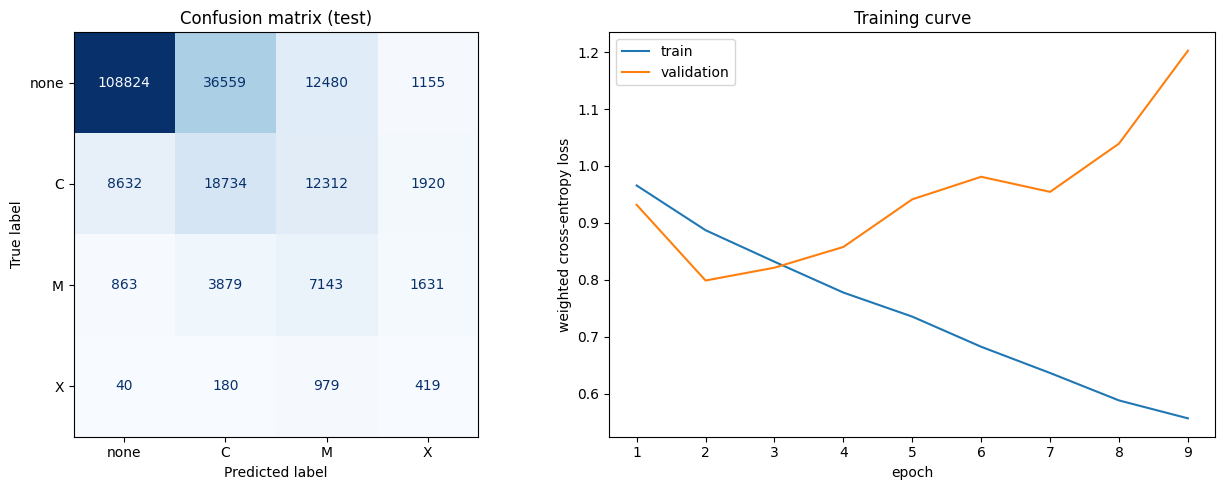

In [ ]:
# WHAT: Plots actual vs predicted classes for the test set, and the loss per epoch.
# OUTPUT: A confusion matrix (diagonal = correct) and a training curve; validation loss rising while training loss
#         falls means the model is memorizing.

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=labels),
                       display_labels=classes).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (test)")
h = np.array(history)
ax[1].plot(range(1, len(h)+1), h[:, 0], label="train"); ax[1].plot(range(1, len(h)+1), h[:, 1], label="validation")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("weighted cross-entropy loss"); ax[1].set_title("Training curve"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5b. Threshold tuning
By default a forecast is whichever class has the **highest** probability, so rare classes (especially X) are almost never predicted. Threshold tuning lowers the bar for the rare classes:

> predict **X** if P(X) ≥ t_X; otherwise **M** if P(M) ≥ t_M; otherwise **C** if P(C) ≥ t_C; otherwise **none**.

- The thresholds t_X, t_M, t_C are chosen on the **validation years (2021–2022)** to maximize mean per-class TSS (one threshold at a time, from several starting points). The test years are not used to choose them.
- If no thresholds beat the default rule on the validation years, the default rule is kept and the notebook says so.
- The chosen thresholds are then applied once to the **test years (2023–2026)**, and the results are compared with the default (highest-probability) rule.
- The model itself is unchanged, so **AUC is the same**; precision, recall, F1 and TSS change.
- Sections 6–8 (example forecasts, snapshot, timeline) still show the default highest-probability predictions.

In [ ]:
# WHAT: Chooses a probability threshold for each rare class (X, then M, then C) on the validation years that
#       maximizes mean per-class TSS. The model is not retrained; only the rule for picking a class changes.
# OUTPUT: The best thresholds, validation mean TSS for default vs tuned, and whether the tuned thresholds are used
#         (only if they beat the default rule on validation).

val_proba = predict_proba(val_dl)
y_val = y_all[val_idx]
none_id = cls2id[classes[0]]                                          # "none"
rare = [cls2id[c] for c in ["X", "M", "C", "B", "A"] if c in cls2id]  # most severe first

def apply_thresholds(p, th):
    """Predict the most severe class whose probability clears its threshold; otherwise 'none'."""
    pred = np.full(len(p), none_id); decided = np.zeros(len(p), bool)
    for k in rare:
        hit = ~decided & (p[:, k] >= th[k])
        pred[hit] = k; decided |= hit
    return pred

def mean_tss(y_true, y_pred):
    vals = []
    for k in range(len(classes)):
        t, p = y_true == k, y_pred == k
        if t.any() and (~t).any():
            vals.append(p[t].mean() - p[~t].mean())
    return np.mean(vals)

GRID = np.round(np.arange(0.01, 1.00, 0.01), 2)
def search(start):
    th = {k: start for k in rare}
    for _ in range(3):                               # coordinate search: tune one threshold at a time, 3 rounds
        for k in rare:
            scores = [mean_tss(y_val, apply_thresholds(val_proba, {**th, k: g})) for g in GRID]
            th[k] = float(GRID[int(np.argmax(scores))])
    return th, mean_tss(y_val, apply_thresholds(val_proba, th))

# Several starting points, keep the best (avoids getting stuck)
th, val_tuned = max((search(s) for s in [0.1, 0.2, 0.3, 0.5, 0.7]), key=lambda r: r[1])
val_default = mean_tss(y_val, val_proba.argmax(1))

# Safety check: only use thresholds if they beat the default rule on the validation years
use_tuned = val_tuned > val_default
print("Best thresholds found:", {classes[k]: th[k] for k in rare})
print(f"Validation mean TSS: default {val_default:.3f} vs tuned {val_tuned:.3f}")
print("-> Using tuned thresholds." if use_tuned else
      "-> Tuned thresholds did not beat the default rule on validation; keeping the default (highest probability).")

Best thresholds found: {'X': 0.11, 'M': 0.45, 'C': 0.42}
Validation mean TSS: default 0.371 vs tuned 0.373
-> Using tuned thresholds.


Per-class metrics, TUNED thresholds (test):


,support,AUC,precision,recall,F1,TSS
none,159018,0.845,0.914,0.675,0.776,0.497
C,41598,0.687,0.299,0.440,0.356,0.193
M,13516,0.833,0.199,0.360,0.256,0.263
X,1618,0.884,0.061,0.482,0.109,0.426



Overall, default vs tuned (test):


,default (highest prob.),tuned thresholds
AUC (macro OvR),0.812,0.812
Precision (macro),0.383,0.368
Recall (macro),0.481,0.489
F1 (macro),0.397,0.374
TSS (mean of per-class),0.343,0.345



M/X vs rest:  default TSS 0.533 (recall 0.672)   ->   tuned TSS 0.550 (recall 0.684)


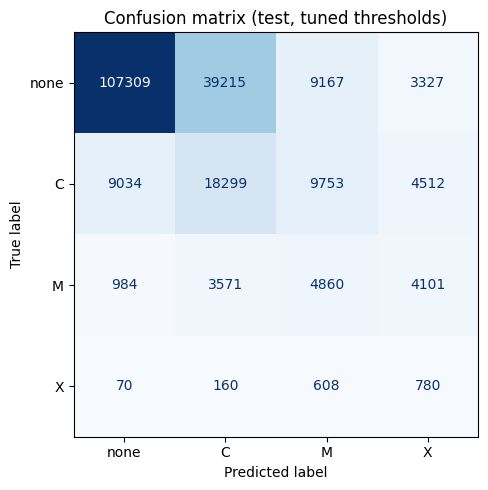

In [ ]:
# WHAT: Applies the chosen thresholds once to the test years and compares with the default rule.
# OUTPUT: Per-class metrics with tuned thresholds, an overall default-vs-tuned table, the M/X-vs-rest score for both,
#         and the tuned confusion matrix.
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred_tuned = apply_thresholds(proba, th) if use_tuned else y_pred
tss_t = tss_per_class(y_test, y_pred_tuned, labels)
per_class_tuned = pd.DataFrame({
    "support":   np.bincount(y_test, minlength=len(classes)),
    "AUC":       per_class["AUC"].values,            # unchanged: AUC does not depend on thresholds
    "precision": precision_score(y_test, y_pred_tuned, labels=labels, average=None, zero_division=0),
    "recall":    recall_score(y_test, y_pred_tuned, labels=labels, average=None, zero_division=0),
    "F1":        f1_score(y_test, y_pred_tuned, labels=labels, average=None, zero_division=0),
    "TSS":       [tss_t[k] for k in labels],
}, index=classes)
summary_tuned = pd.Series({
    "AUC (macro OvR)":   np.nanmean(per_class_tuned["AUC"]),
    "Precision (macro)": precision_score(y_test, y_pred_tuned, average="macro", zero_division=0),
    "Recall (macro)":    recall_score(y_test, y_pred_tuned, average="macro", zero_division=0),
    "F1 (macro)":        f1_score(y_test, y_pred_tuned, average="macro", zero_division=0),
    "TSS (mean of per-class)": np.nanmean(per_class_tuned["TSS"]),
})

def mx_tss(pred):
    big = [cls2id[c] for c in ["M", "X"] if c in cls2id]
    t, p = np.isin(y_test, big), np.isin(pred, big)
    return p[t].mean() - p[~t].mean(), p[t].mean()
d_tss, d_rec = mx_tss(y_pred); t_tss, t_rec = mx_tss(y_pred_tuned)

print("Per-class metrics, TUNED thresholds (test):"); display(per_class_tuned.round(3))
print("\nOverall, default vs tuned (test):")
display(pd.DataFrame({"default (highest prob.)": summary, "tuned thresholds": summary_tuned}).round(3))
print(f"\nM/X vs rest:  default TSS {d_tss:.3f} (recall {d_rec:.3f})   ->   tuned TSS {t_tss:.3f} (recall {t_rec:.3f})")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_tuned, labels=labels),
                       display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (test, tuned thresholds)")
plt.tight_layout(); plt.show()

## 6. Example forecasts
Each row below is **one forecast**: one active region at one hour. The model has seen that region's previous `SEQ_LEN` hours of magnetic-field measurements and gives the probability of each outcome for the next 24 hours. `predicted_class` is the most likely one; `actual` is what really happened.

Note: the class weighting inflates the probabilities of rare classes, so treat them as a ranking rather than real-world odds.

In [ ]:
# WHAT: Builds a table of every test forecast (time, region, actual, predicted, probability for each class).
# OUTPUT: The first 10 rows (usually one region hour by hour). Class weighting inflates rare-class probabilities,
#         so treat P(...) as rankings, not true odds.

def forecast_table(idx, proba):
    out = df.loc[idx, ["time", "HARPNUM", "NOAA_AR"]].copy()
    out["actual"] = df.loc[idx, "y_class"].values
    out["predicted_class"] = [classes[i] for i in proba.argmax(1)]
    for k, c in enumerate(classes):
        out[f"P({c})"] = proba[:, k].round(3)
    return out

test_forecasts = forecast_table(test_idx, proba)
test_forecasts.head(10)

,time,HARPNUM,NOAA_AR,actual,predicted_class,P(none),P(C),P(M),P(X)
351395,2023-01-04 22:00:00,8950,13182,C,C,0.258,0.353,0.309,0.080
351396,2023-01-04 23:00:00,8950,13182,C,C,0.231,0.391,0.336,0.043
351397,2023-01-05 00:00:00,8950,13182,C,C,0.213,0.410,0.346,0.031
351398,2023-01-05 01:00:00,8950,13182,X,C,0.207,0.423,0.346,0.024
351399,2023-01-05 02:00:00,8950,13182,X,C,0.197,0.435,0.349,0.019
351400,2023-01-05 03:00:00,8950,13182,X,C,0.196,0.450,0.340,0.014
351401,2023-01-05 04:00:00,8950,13182,X,C,0.195,0.465,0.330,0.010
351402,2023-01-05 05:00:00,8950,13182,X,C,0.194,0.477,0.322,0.007
351403,2023-01-05 06:00:00,8950,13182,X,C,0.196,0.486,0.311,0.007
351404,2023-01-05 07:00:00,8950,13182,X,C,0.198,0.501,0.296,0.005


One row is one forecast: the model looks at one sunspot region at one hour and predicts the biggest flare that region will produce over the next 24 hours.

## 7. Snapshot: every region at one hour
What a real forecast looks like: **all regions on the Sun at a single hour**, ranked by how likely the model thinks an M or X flare is in the next 24 hours, next to what actually happened.

- Set `SNAPSHOT_TIME` to any test hour (e.g. `"2024-05-10 12:00"`). Left as `None`, it picks the test hour with the most regions about to produce M/X flares.
- A good model puts the regions that really flared (dark bars) at the top, even if the exact class is off.
- **actual** is the biggest flare class in the next 24 h; **peak** is that flare's exact size.

2024-12-28 19:00: 8 regions tracked, 5 went on to produce an M/X flare.
The model's top 5 by P(M or X) contain 4 of those 5.


,NOAA_AR,HARPNUM,actual,peak,predicted_class,P(M or X),P(none),P(C),P(M),P(X)
0,13932,12456,M,M1.2,M,0.804,0.004,0.192,0.787,0.017
1,13939,12492,M,M3.5,M,0.782,0.027,0.191,0.753,0.029
2,13936,12471,X,X1.1,X,0.723,0.060,0.217,0.244,0.479
3,13929,12466,M,M1.0,M,0.613,0.024,0.363,0.612,0.001
4,13944,12506,none,quiet,none,0.047,0.553,0.400,0.047,0.000
5,13934,12477,M,M3.3,none,0.003,0.767,0.230,0.003,0.000
6,13937,12481,none,quiet,none,0.003,0.948,0.049,0.003,0.000
7,13935,12479,none,quiet,none,0.002,0.948,0.050,0.002,0.000


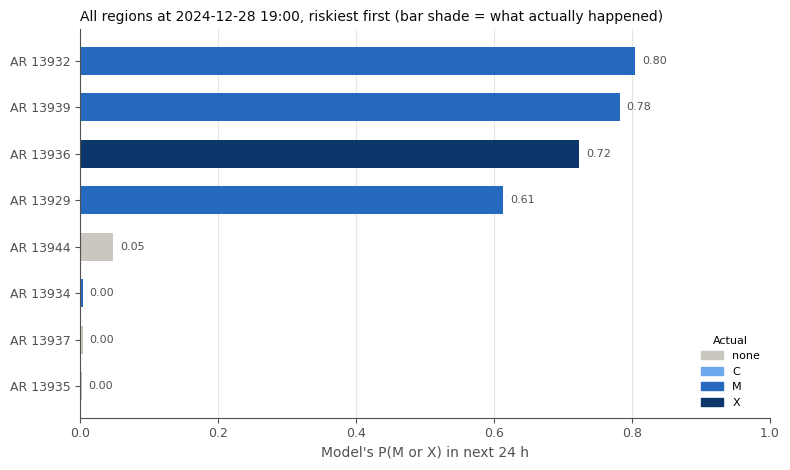

In [ ]:
# WHAT: Snapshot of one hour: every region on the Sun at SNAPSHOT_TIME (default: busiest test hour), ranked by
#       the model's P(M or X), next to what actually happened.
# OUTPUT: A summary line, a table of those regions, and a bar chart (bar length = P(M or X), shade = actual class).

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
# Flare classes are ordered by size, so they share one blue ramp (light = small, dark = big); "none" is neutral gray.
CLASS_COLOR = {"none": "#c9c7bf", "B": "#9ec5f4", "C": "#6da7ec", "M": "#256abf", "X": "#0d366b"}
INK, MUTED = "#0b0b0b", "#52514e"
def tidy(ax):
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(MUTED); ax.spines["bottom"].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=9); ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)

tf = test_forecasts.copy()
tf["peak"] = df.loc[tf.index, "GOES_CLASS"].values           # actual peak flare, e.g. "X1.1"
big = [c for c in ["M", "X"] if c in classes]
tf["P(M or X)"] = tf[[f"P({c})" for c in big]].sum(axis=1).round(3)

SNAPSHOT_TIME = None      # e.g. "2024-12-28 19:00"; None = busiest test hour in the data loaded

if SNAPSHOT_TIME is None:
    busy = (tf.assign(is_big=tf.actual.isin(big)).groupby("time")
              .agg(big_flares=("is_big", "sum"), regions=("HARPNUM", "size"))
              .sort_values(["big_flares", "regions"], ascending=False))
    snap_time = busy.index[0]
else:
    snap_time = pd.Timestamp(SNAPSHOT_TIME)
snap = tf[tf.time == snap_time].sort_values("P(M or X)", ascending=False)

if snap.empty:
    print(f"No test forecasts at {snap_time}. Pick an hour between {tf.time.min()} and {tf.time.max()}.")
else:
    n_big = snap.actual.isin(big).sum()
    hits = snap.head(n_big).actual.isin(big).sum() if n_big else 0
    print(f"{snap_time:%Y-%m-%d %H:%M}: {len(snap)} regions tracked, {n_big} went on to produce an M/X flare.")
    if n_big:
        print(f"The model's top {n_big} by P(M or X) contain {hits} of those {n_big}.")
    display(snap[["NOAA_AR", "HARPNUM", "actual", "peak", "predicted_class", "P(M or X)"] + [f"P({c})" for c in classes]]
            .reset_index(drop=True))

    fig, ax = plt.subplots(figsize=(8, 0.45 * len(snap) + 1.2))
    labels = [f"AR {a}" if a else f"HARP {h}" for a, h in zip(snap.NOAA_AR, snap.HARPNUM)]
    ax.barh(labels[::-1], snap["P(M or X)"][::-1], color=[CLASS_COLOR[c] for c in snap.actual[::-1]], height=0.6)
    for y, v in enumerate(snap["P(M or X)"][::-1]):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8, color=MUTED)
    ax.set_xlim(0, 1); ax.set_xlabel("Model's P(M or X) in next 24 h", color=MUTED)
    ax.set_title(f"All regions at {snap_time:%Y-%m-%d %H:%M}, riskiest first (bar shade = what actually happened)",
                 fontsize=10, color=INK, loc="left")
    ax.legend(handles=[Patch(color=CLASS_COLOR[c], label=c) for c in classes], title="Actual",
              frameon=False, fontsize=8, title_fontsize=8, loc="lower right")
    tidy(ax); plt.tight_layout(); plt.show()

## 8. Timeline: one region hour by hour
Follows **one active region** across its whole time on the visible Sun and plots the model's forecast every hour.

- **Top panel:** the model's P(C), P(M) and P(X) for the next 24 hours.
- **Bottom strips:** what actually happened in the next 24 hours vs. what the model predicted, colored by class.
- Look for whether P(M)/P(X) **rise before** the dark (M/X) periods begin and fall after they end.
- Set `TIMELINE_HARPNUM` to any test region. Left as `None`, it picks the test region with the most X-flare hours. On the full test set (and in the smoke test, via `ALWAYS_INCLUDE`) that is HARPNUM 11149 = **NOAA AR 13664**, the region behind the May 2024 geomagnetic storm.

HARPNUM 11149 (NOAA AR 13664): 2024-04-30 05:00 -> 2024-05-14 23:00, 327 hourly forecasts
Hours by actual class: {'none': 23, 'C': 60, 'M': 92, 'X': 152}


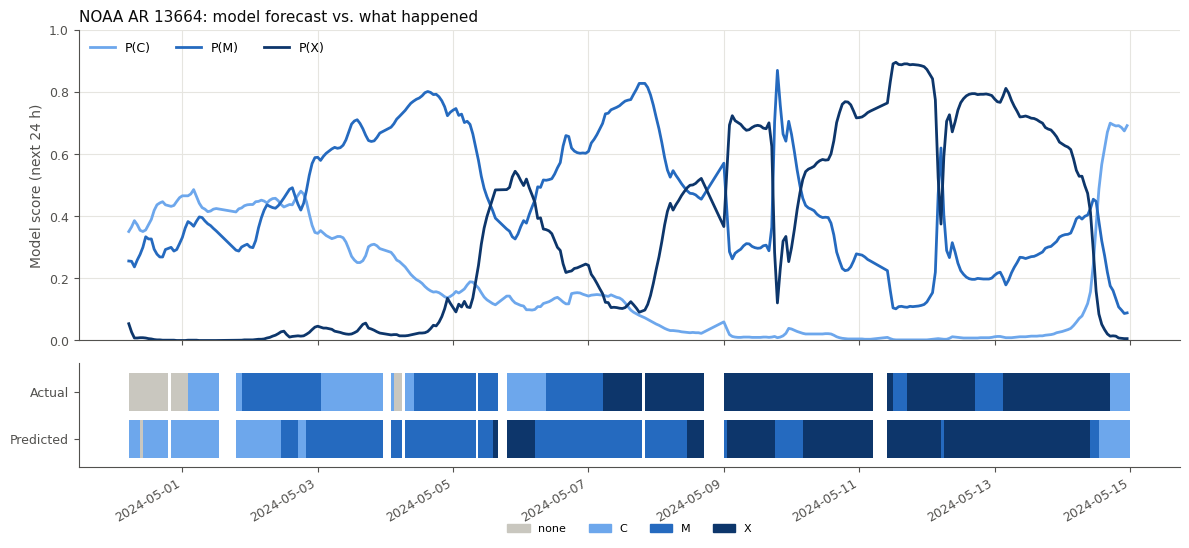


This region, actual (rows) vs predicted (columns), in hours:


predicted_class,none,C,M,X
actual,,,,
none,1,19,3,0
C,0,20,30,10
M,0,17,58,17
X,0,4,44,104


In [ ]:
# WHAT: Timeline of one region (default: the test region with the most X hours, AR 13664) across its whole time
#       on the visible Sun.
# OUTPUT: A chart of P(C)/P(M)/P(X) each hour with actual vs predicted strips below, and an actual-vs-predicted
#         table (in hours) for that region.

TIMELINE_HARPNUM = None   # e.g. 11149 (NOAA AR 13664); None = test region with the most X (then M) hours

if TIMELINE_HARPNUM is None:
    counts = pd.crosstab(tf.HARPNUM, tf.actual).reindex(columns=big[::-1] + ["C", "none"], fill_value=0)
    TIMELINE_HARPNUM = counts.sort_values(list(counts.columns), ascending=False).index[0]
r = tf[tf.HARPNUM == TIMELINE_HARPNUM].sort_values("time")

if r.empty:
    print(f"HARPNUM {TIMELINE_HARPNUM} is not in the test forecasts. Test regions:", sorted(tf.HARPNUM.unique())[:20], "...")
else:
    ar = r.NOAA_AR.iloc[0]
    print(f"HARPNUM {TIMELINE_HARPNUM} (NOAA AR {ar}): {r.time.min():%Y-%m-%d %H:%M} -> {r.time.max():%Y-%m-%d %H:%M}, {len(r)} hourly forecasts")
    print("Hours by actual class:", r.actual.value_counts().reindex(classes, fill_value=0).to_dict())

    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    for c in [c for c in ["C", "M", "X"] if c in classes]:
        ax.plot(r.time, r[f"P({c})"], color=CLASS_COLOR[c], lw=2, label=f"P({c})")
    ax.set_ylim(0, 1); ax.set_ylabel("Model score (next 24 h)", color=MUTED)
    ax.set_title(f"NOAA AR {ar}: model forecast vs. what happened", fontsize=11, color=INK, loc="left")
    ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper left"); tidy(ax); ax.grid(axis="y", color="#e6e5e0", lw=0.8)

    w = pd.Timedelta(hours=1)
    for row, col in [(1, "actual"), (0, "predicted_class")]:
        ax2.bar(r.time, 0.8, width=w, bottom=row - 0.4, align="edge", color=[CLASS_COLOR[c] for c in r[col]], linewidth=0)
    ax2.set_yticks([1, 0]); ax2.set_yticklabels(["Actual", "Predicted"]); ax2.set_ylim(-0.6, 1.6)
    ax2.legend(handles=[Patch(color=CLASS_COLOR[c], label=c) for c in classes], frameon=False, fontsize=8,
               ncol=len(classes), loc="upper center", bbox_to_anchor=(0.5, -0.45))
    tidy(ax2); ax2.grid(False); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

    print("\nThis region, actual (rows) vs predicted (columns), in hours:")
    display(pd.crosstab(r.actual, r.predicted_class).reindex(index=classes, columns=classes, fill_value=0))

**References:** Wang, Z., Yan, W., & Oates, T. (2017). Time series classification from scratch with deep neural networks: A strong baseline. *IJCNN*. · Li, P., Bahri, O., Filali Boubrahimi, S., & Hamdi, S. M. (2025). *ApJS*, 280(2), 52. https://doi.org/10.3847/1538-4365/adfa2a